# Sovereign Clearing Audit
## tl;dr
El componente estático del programa soberano-bancario avanza a S2 parcial: balance, pagos pro-rata, LP y oráculo racional. Impago bruto no equivale a pérdida social. Un residual pequeño no certifica precisión de pagos en redes casi cerradas.

## Context & Methods
### Key Assumptions
L[i,j] es deuda de i con j; l_i es deuda externa; pbar_i=sum_j L[i,j]+l_i; Pi[i,j]=L[i,j]/pbar_i. Cada deudor debe algo fuera del sistema. Activos disponibles x_i(h)=cash_i+(1-h)*sovereign_i, liquidables al precio fijo supuesto. No hay precio endógeno, haircut estimado, costos de quiebra ni rescate.
$$p=\min(\bar p,x+\Pi^Tp).$$
La iteración desde0 y pbar produce cotas en aritmética exacta; se para por ancho L1≤1e-8. La implementación flotante no es aritmética de intervalos con redondeo dirigido.

In [1]:
import sys,json,csv
from pathlib import Path
import numpy as np
sys.path.insert(0,str(Path('src').resolve()))
from clearing import Network,assets,bracket,lp_clear,rational_clear,accounting
config=json.loads(Path('results/config.json').read_text())
net=Network(np.array(config['liabilities']),np.array(config['outside']))
x=assets(net,np.array(config['cash']),np.array(config['sovereign']),1.)
r=bracket(net,x)
print('Pagos iterativos:',r.payments)
print('Pagos racionales:',rational_clear(net,x))
print('Ancho L1:',r.width_l1,'; LP error:',abs(lp_clear(net,x)-r.payments).sum())

Pagos iterativos: [0.63099631 0.66789668 0.70110701]
Pagos racionales: (Fraction(171, 271), Fraction(181, 271), Fraction(190, 271))
Ancho L1: 9.251838073431884e-09 ; LP error: 1.5419725496457204e-09


### Por qué el residual no basta
En este alcance anclado, beta=max_i sum_j Pi[i,j]<1. El mínimo por componente es1-Lipschitz y la norma1 inducida de Pi transpuesta es beta. Por tanto:
$$\|F(p)-F(q)\|_1\leq\beta\|p-q\|_1,\quad \|p-p^*\|_1\leq\frac{\|F(p)-p\|_1}{1-\beta}.$$
Es un argumento estándar condicionado al modelo y aritmética exacta, no una garantía formal del cálculo flotante. Al acercarse beta a1, un residual minúsculo puede coexistir con un error grande. El benchmark incluye una parada residual ajustada para una comparación de precisión más justa.

## Data
Balances, shocks y redes son sintéticos, seed20261018. La exposición soberana es un supuesto de balance, no datos TES. El contrafactual de una sola pasada usa cobros contractuales completos: no es otro equilibrio. Se compara también con el notebook estructural semanal existente, sin presentarlo como OLS genérico.

In [2]:
print(config)
print('Conciliación al haircut total:',accounting(net,x,r.payments))
print(Path('results/weekly_regression.csv').read_text())

{'liabilities': [[0.0, 0.9, 0.0], [0.0, 0.0, 0.9], [0.9, 0.0, 0.0]], 'outside': [0.1, 0.1, 0.1], 'cash': [0.0, 0.1, 0.1], 'sovereign': [0.1, 0.0, 0.0], 'haircuts': [0.0, 0.1, 0.2, 0.30000000000000004, 0.4, 0.5, 0.6000000000000001, 0.7000000000000001, 0.8, 0.9, 1.0], 'oracle_cases': 30, 'scale_banks': [8, 32, 128], 'max_iterations': 10000, 'near_anchors': [0.1, 0.01, 0.001, 1e-09]}
Conciliación al haircut total: {'gross_unpaid': 1.0000000015419728, 'outside_unpaid': 0.1000000001541973, 'outside_payment': 0.19999999984580275, 'equity': 3.0839464315590703e-10, 'resource_identity_error': -1.5419737708910475e-10}
haircut,notebook_gross,modular_gross,difference
0.0,2.0,2.0,0.0
0.25,2.5999999999999996,2.5999999999999996,0.0
0.5,3.5999999999999996,3.5999999999999996,0.0
0.75,4.6,4.6,0.0
1.0,5.6,5.6,0.0



## Results
En la economía pro-rata sin quiebra costosa, los pagos internos se cancelan al consolidar.
$$\sum_i x_i=\sum_i (l_i/\bar p_i)p_i+\sum_i E_i.$$
Por eso contar impagos de todas las obligaciones internas repetidamente no mide una pérdida agregada de bienestar.

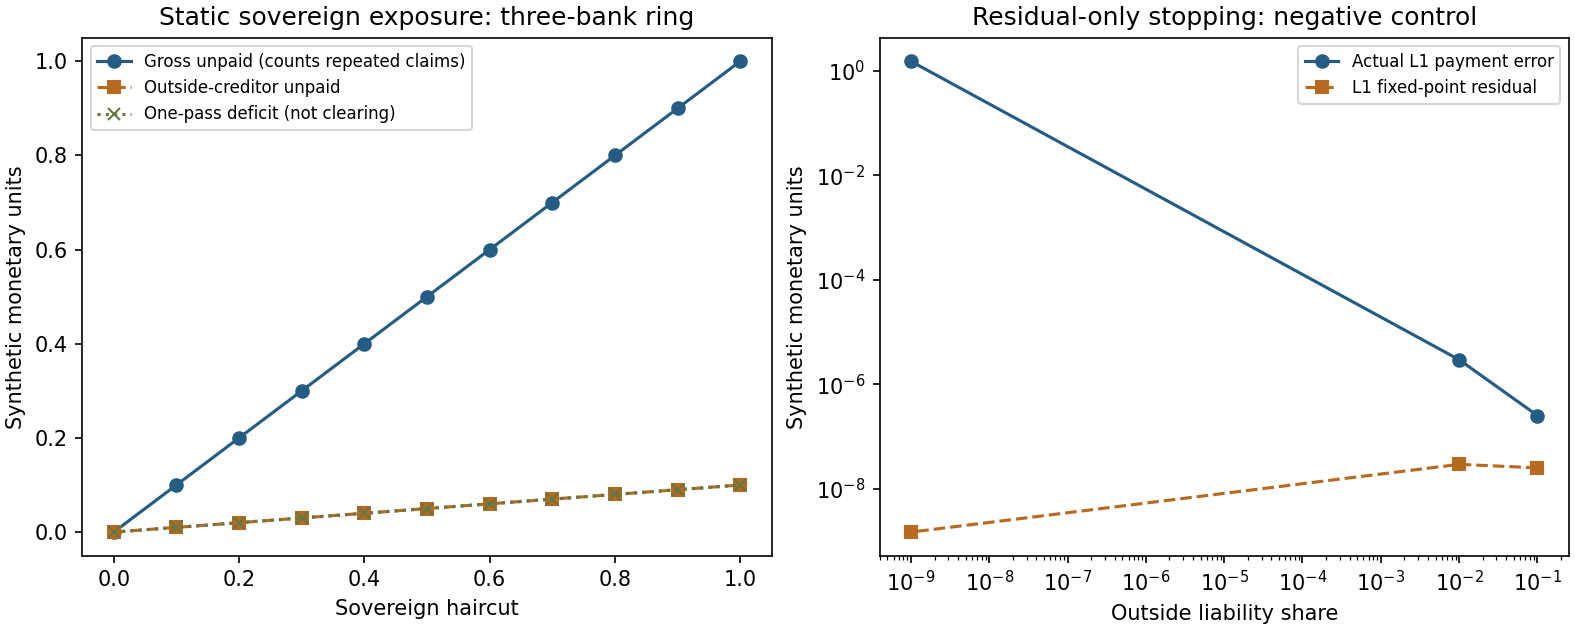

In [3]:
from IPython.display import Image,display
display(Image(filename='results/comparison.png'))

### Control negativo y contraste independiente
Para ancla externa1e-9 y recursos5e-10 por banco, la referencia racional paga1/2 cada banco. La parada por residual y el éxito nominal de LP pueden dar errores L1 cercanos a1.5. El esquema de cotas rechaza por presupuesto: es una limitación de alcance, no una solución rápida.

In [4]:
for row in csv.DictReader(Path('results/near_closed.csv').open()):
    if float(row['anchor'])==1e-9: print(row)
print(Path('results/coverage.txt').read_text())
print(json.loads(Path('results/metadata.json').read_text()))

{'anchor': '1e-09', 'method': 'residual_only', 'status': 'accepted', 'iterations': '1', 'residual_l1': '1.4999997910436491e-09', 'error_l1': '1.4999999985000003', 'width_l1': '', 'seconds': '7.130699998469936e-05'}
{'anchor': '1e-09', 'method': 'two_sided', 'status': 'Payment bracket did not close: width=2.9999700001520737, iterations=10000', 'iterations': '10000', 'residual_l1': '', 'error_l1': '', 'width_l1': '', 'seconds': '0.31615889800002606'}
{'anchor': '1e-09', 'method': 'LP', 'status': 'solver_success_not_accuracy_certificate', 'iterations': '', 'residual_l1': '1.4999997910436491e-09', 'error_l1': '1.5', 'width_l1': '', 'seconds': ''}
Name              Stmts   Miss Branch BrPart  Cover   Missing
-------------------------------------------------------------
src/clearing.py     122      1     42      1    99%   167
-------------------------------------------------------------
TOTAL               122      1     42      1    99%

{'seed': 20261018, 'python': '3.12.14', 'platform': 

## Takeaways
Evidencia de implementación y contabilidad, no causalidad ni validación bancaria. El juego dinámico, feedback fiscal, garantías, colateral y fire sales siguen S1. Ver informe.md: errores, presupuestos, benchmarks, prior art y límites. Las cotas flotantes se contrastan empíricamente con Fraction/LP; no se afirma un teorema numérico nuevo.